# Ising: seed sensitivity and a corrected MC reference
**Weekly research update · 31 October 2026**

**Two questions:** Why did retraining change the TM prediction? Why was the original MC result anomalous at $T=0.3$?

The seed experiment identifies training sensitivity. The low-temperature experiment identifies trapping in the original single-spin MC sampler and repairs the reference using a separately validated Wolff implementation.

**Reading route:** Sections 1–7 contain the results and figures. The appendix contains the cleaned experiment code.

**Presentation mode:** All figures are embedded and open without the repository or checkpoint. `Run All` with the switches below left at `False` does not train, sample, or write experiment files. To rerun experiments, place this notebook in the repository root and configure the paths below. Reruns write new files; the presentation figures remain the explicitly dated archived results.


In [1]:
from pathlib import Path
from datetime import datetime

# Presentation mode: keep all switches False during the meeting.
RUN_SAMPLING_CHECKS = True
RUN_TRAINING_STUDY = True
RUN_LOW_T_STUDY = True
RUN_FINAL_COMPARISON = True

PROJECT_ROOT = Path.cwd()
ORIGINAL_CHECKPOINT = Path("C:/content/models/model_19.pt")
EXISTING_REFERENCE = (
    PROJECT_ROOT / "runs" / "ising_low_temperature"
    / "wolff_reference_20261031_195629_751347"
)

# A new session directory prevents overwriting the recorded experiments.
EXPERIMENT_ROOT = (
    PROJECT_ROOT / "runs"
    / f"ising_meeting_rerun_{datetime.now():%Y%m%d_%H%M%S_%f}"
)
RERUN_ANY = any((RUN_SAMPLING_CHECKS, RUN_TRAINING_STUDY,
                 RUN_LOW_T_STUDY, RUN_FINAL_COMPARISON))
print("Mode:", "selected experiments" if RERUN_ANY else "presentation only")


Mode: selected experiments


## 1. What is being measured?

The system is the **$8\times8$ ferromagnetic Ising model**, with $J=1$, zero field and periodic boundaries. We compare absolute magnetization per spin and total energy:

$$|m|=\left|\frac{1}{64}\sum_i s_i\right|,\qquad
E=-\sum_{\langle i,j\rangle}s_i s_j,\quad s_i\in\{-1,+1\}.$$

Each bond is counted once. An aligned configuration has $|m|=1$ and $E=-128$.

**Source versus addition:** the original notebook used `SingleSpinFlipSampler`. We added the seed controls, diagnostics and a Wolff cluster implementation. The Wolff algorithm itself is an established method; it is not a new algorithm proposed here.


## 2. Sampling randomness is not training randomness

**First hold the trained checkpoint fixed.** Resetting the sampling seed to 42 produced identical arrays on this CPU environment: maximum absolute difference **0.0**. Changing the seed to 43 changed the generated samples.

With 500 generated configurations per seed at **T = 3.3**, the fixed-checkpoint means were similar:

| Sampling seed | Mean absolute magnetization | Mean total energy |
|---|---:|---:|
| 42 | 0.3896 ± 0.0107 | −55.296 ± 0.779 |
| 43 | 0.3695 ± 0.0110 | −54.568 ± 0.843 |
| 44 | 0.3855 ± 0.0108 | −55.024 ± 0.839 |

Values are rounded notebook outputs; ± denotes estimated sampling SEM. This checks repeatability for this checkpoint, environment and sampling configuration. It does not establish identical results across devices or repeated training.

**Then vary the training seed.** Keep the newly generated training data, 80/20 split, preprocessing noise, architecture and training settings fixed. Train fresh models with seeds 42 and 43; evaluate both with sampling seed 2027.

The shared dataset contains 10,000 configurations at T = 1.5 and 2.5 (8,000 training; 2,000 held out). Training uses 20 epochs, batch size 8 and 100 diffusion steps. This dataset was generated for the controlled experiment; it was not recovered from the historical Mac run.


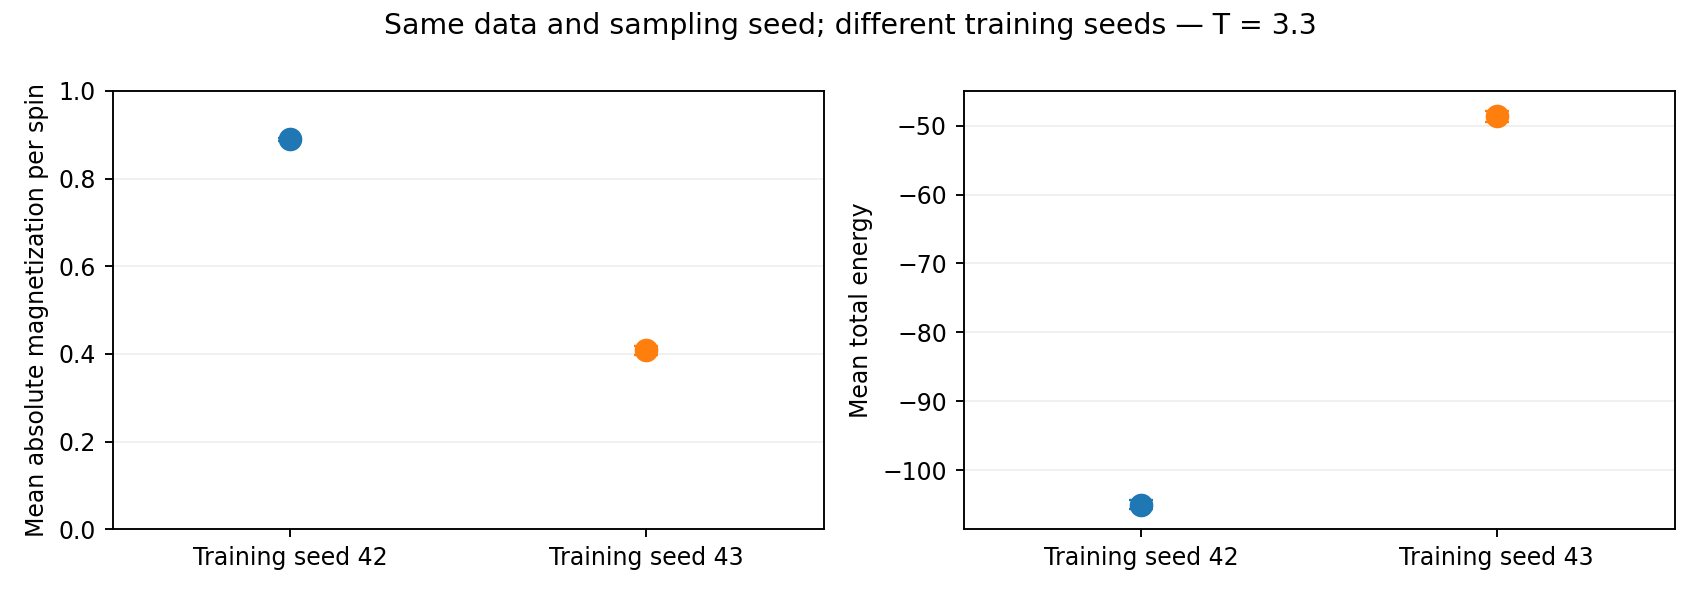

*Replotted from rounded saved outputs: 500 samples per model, sampling seed 2027; error bars are sampling SEM, not training variability.*


**Finding:** training seeds 42 and 43 give mean absolute magnetizations **0.8894** and **0.4078**, and mean energies **−105.000** and **−48.656**, respectively. The large difference remains after controlling sampling randomness.

**Interpretation:** this training setup is seed-sensitive. Fixing seeds makes a run traceable; it does not make its physical predictions accurate. Two training seeds do not characterize the full distribution of training outcomes. The random-frame train/test split also does not guarantee physically independent holdout data.


## 3. Why was the original MC result anomalous at T = 0.3?

**Hypothesis:** local single-spin updates become trapped in stripe configurations at low temperature.

We held the model and temperature fixed, changed the initial state, and repeated seeds 42–44. Each run used 1,000 warm-up sweeps followed by 5,000 measurement sweeps.


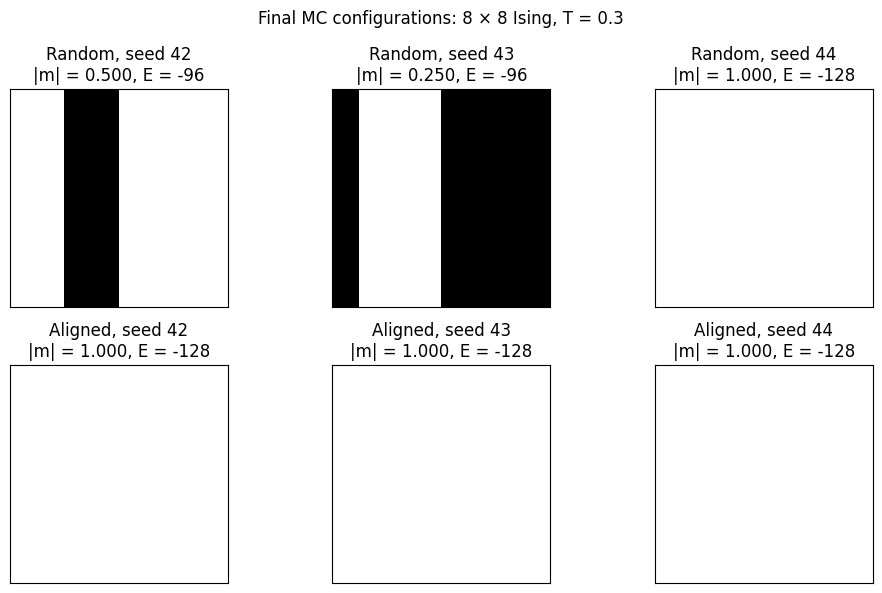

*Archived final configurations from all six original-sampler runs. Random starts sometimes retain stripes; aligned starts remain aligned.*


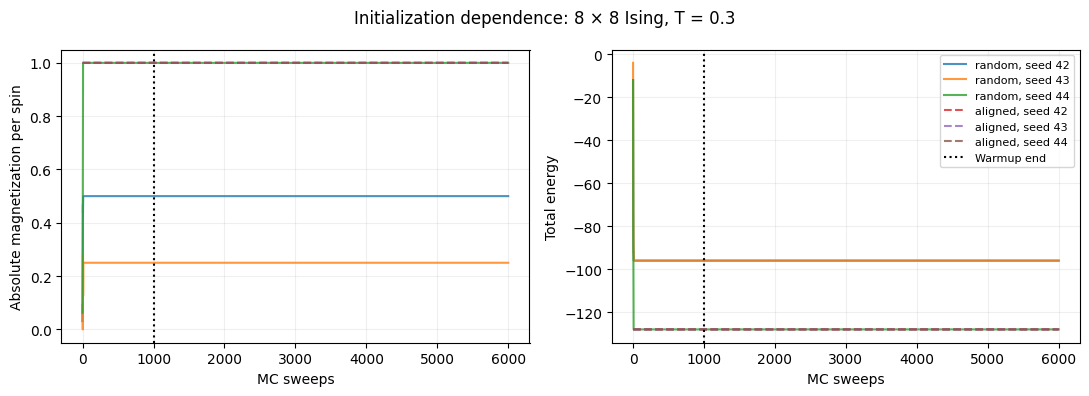

*Archived trajectories: flat observables can reflect trapping. A flat trace alone is not evidence of equilibration.*


The trapped runs have $E=-96$, while an aligned configuration has $E=-128$. Two straight periodic domain walls contain 16 unsatisfied bonds, giving an energy cost of $16\times2=32$.

**Physical explanation:** moving out of a straight stripe by local flips requires thermally activated moves. At low temperature these are strongly suppressed. The issue is sampling within the available run time; these tests do not isolate a general system-size effect.


## 4. A controlled temperature check

Start every run from the **same observed stripe**, then compare T = 0.3 and T = 1.0 with the original sampler.


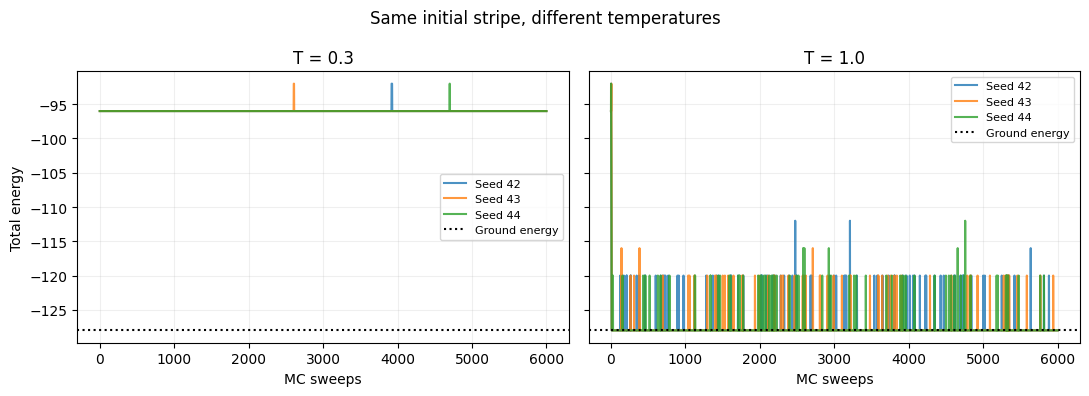

*Archived temperature control: no ground-state visit was observed at T = 0.3 within 6,000 sweeps; first visits at T = 1.0 occurred after 7, 10 and 9 sweeps.*


**Finding:** raising the temperature lets the stripe escape in these runs. This supports an activated trapping explanation. A first visit to the ground state is not, by itself, a complete mixing-time test.


## 5. Repair the reference with a validated Wolff sampler

Wolff grows a cluster of like spins, adding eligible neighbors with probability

$$p_{\mathrm{add}}=1-\exp(-2J/T),$$

and flips the whole cluster. It targets the same equilibrium Ising distribution while allowing collective moves.

Our implementation includes both periodic boundaries. Basic checks cover the single-spin limit, wrap-around connectivity and seed repeatability. We then compared the sampled observables with **exact enumeration of all 512 states of a 3×3 lattice** at T = 2.5 and 4.0, using three seeds.

At both temperatures, all six runs' mean magnetization and energy estimates were within approximately 1.3 reported block SEM of the exact values. This supports the implementation at those tested conditions; it is not a universal correctness proof.

**Update units:** one Wolff cluster update is not one single-spin MC sweep and should not be interpreted as physical dynamics.


<details>
<summary>Exact-enumeration check: recorded numerical output</summary>

```text
T = 2.5
Exact: |m| = 0.816861, E = -13.159102
Seed 42: |m| = 0.814500 +/- 0.002296; E = -13.114800 +/- 0.057323
Seed 43: |m| = 0.816322 +/- 0.002328; E = -13.135200 +/- 0.056810
Seed 44: |m| = 0.814867 +/- 0.002173; E = -13.108600 +/- 0.051284

T = 4.0
Exact: |m| = 0.542075, E = -6.723062
Seed 42: |m| = 0.540656 +/- 0.002577; E = -6.650000 +/- 0.059635
Seed 43: |m| = 0.542433 +/- 0.002583; E = -6.738400 +/- 0.058406
Seed 44: |m| = 0.541322 +/- 0.002453; E = -6.722800 +/- 0.056785

Uncertainties are approximate block-based standard errors.
```

</details>


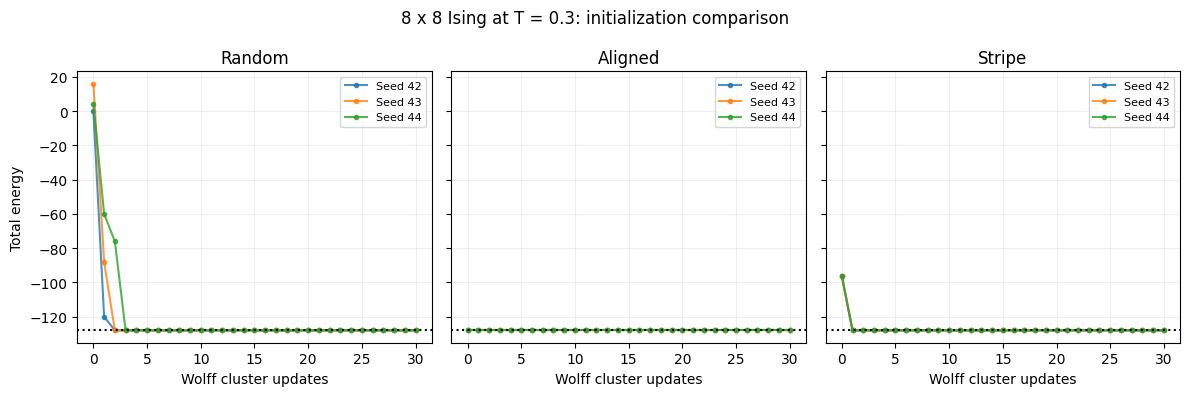

*Archived Wolff test at T = 0.3: random, aligned and stripe starts all reach the ground-state energy. These axes count cluster updates, not MC sweeps.*


After 100 warm-up cluster updates, all nine runs gave mean absolute magnetization 1.0000 and mean total energy −128.000 over 1,000 measured updates. No excited state was observed in these measured windows; this does not imply exactly zero equilibrium excitation probability.


## 6. Rebuild the full MC reference

We kept the original 16 temperatures (0.3 to 3.3 in steps of 0.2). At each temperature: two initializations × three seeds, 1,000 warm-up cluster updates, then 10,000 measurements. Every cluster update is measured.


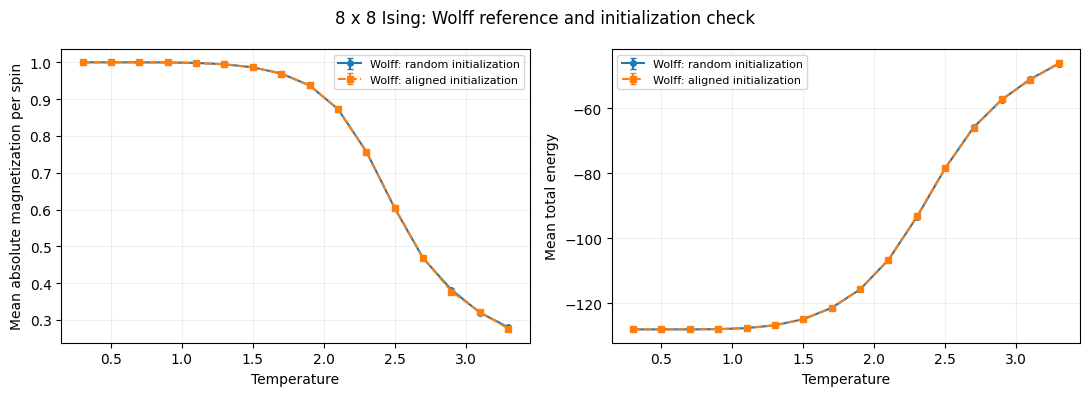

*Archived full reference: random and aligned initialization means are close. Within each initialization, error bars use approximate block-based SEM across three seeds.*


**Uncertainty limits:** the two initializations reuse update seeds, so their errors are correlated. Their near overlap is a useful diagnostic, not an equivalence test with independent replicates. The final comparison below accounts conservatively for this pairing when combining block SEMs. A full block-size and late-window convergence audit remains separate; zero observed variation at low temperature does not establish zero uncertainty.


## 7. Corrected MC–TM comparison

The TM curve uses the **original checkpoint**, not either of the two new training-seed models. We generated 500 configurations per temperature, batch size 20, sampling seed 2026, with gamma = eta = 1 and 100 diffusion steps. No TM retraining was performed for this figure.


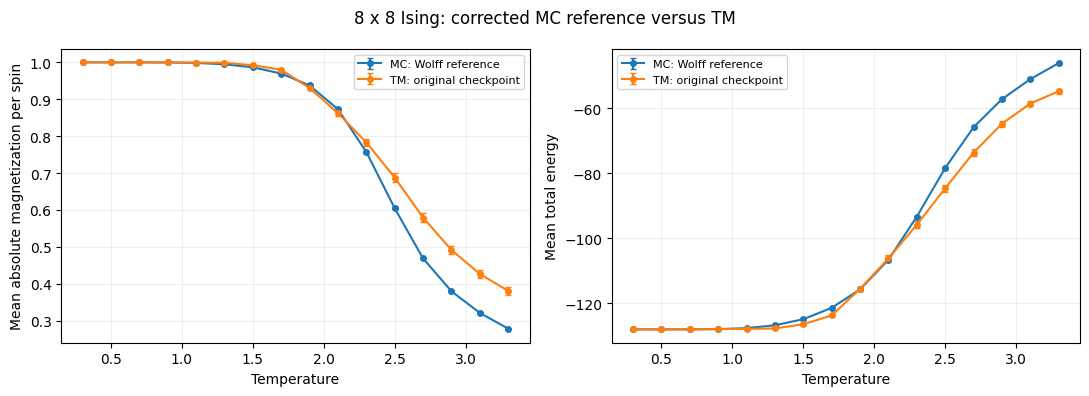

*Archived corrected comparison. Error bars describe estimated sampling uncertainty; they do not include training-seed variability. The same TM sampling seed is reused across temperatures.*


| Temperature | Wolff mean absolute magnetization | TM mean absolute magnetization | Wolff mean energy | TM mean energy |
|---|---:|---:|---:|---:|
| 0.3 | 1.0000 | 1.0000 | −128.000 | −128.000 |
| 2.5 | 0.6043 | 0.6877 | −78.394 | −84.640 |
| 3.3 | 0.2782 | 0.3804 | −46.166 | −54.824 |

**Low-temperature finding:** the original MC anomaly is removed by changing the sampler at fixed system size and temperature.

**Remaining TM discrepancy:** at higher temperatures this checkpoint produces higher absolute magnetization and lower energy than the corrected reference. Its configurations are biased toward greater order. The comparison identifies the discrepancy, but does not identify its unique training or model-level cause.

### Questions remaining

- How much of the TM error varies across training seeds, and which training changes improve robustness?
- Do training-data sampling and validation procedures need stronger equilibration and independence checks?
- For ExpTM lattice gas, which exact checkpoint, control-variable mapping and decoding procedure match the paper?

### Current status

**Task 1:** sampling repeatability demonstrated; controlled training-seed sensitivity identified. Training robustness remains open.  
**Task 2:** the observed T = 0.3 MC trapping anomaly has been diagnosed and repaired for this setup; the full reference and comparison are rebuilt. This does not certify TM accuracy over the full temperature range.  
**Next:** continue the ExpTM lattice-gas reproduction, followed by the independent lattice-gas simulation.


---
## Appendix — experiment code and provenance

**For the meeting, stop at Section 7.** The cells below are collapsed implementation details. Leave the four switches at the top set to `False` to preserve a fast presentation-only workflow.

To reproduce selected studies, change the relevant switches and run the notebook from the top in a fresh kernel:

- `RUN_SAMPLING_CHECKS`: fixed-checkpoint seed tests (about 3 minutes in the recorded environment).
- `RUN_TRAINING_STUDY`: generate one fixed dataset, train **both** seeds 42 and 43, then compare them with sampling seed 2027 (about 40 minutes).
- `RUN_LOW_T_STUDY`: original-MC diagnostics, Wolff unit checks, exact enumeration comparison, low-T initialization check and full reference (a few minutes).
- `RUN_FINAL_COMPARISON`: load the new reference if generated in this session; otherwise use `EXISTING_REFERENCE`. This requires the original checkpoint (about 13 minutes).

Imports require the repository's installed dependencies. The original checkpoint and the raw `runs/` directory are not embedded in this notebook. Paths must be updated on a different machine.

The presentation preserves the original saved figure bytes. Numerical summaries come from the uploaded notebook's recorded output; the training-seed figure is newly plotted from those rounded values. These results were not recomputed during cleanup. The appendix has been refactored and syntax-checked; its full PyTorch experiment path has not been re-executed here.

Changes to the code: centralized imports and seed reset; one shared observable summary; both training seeds in an explicit loop; unique rerun output directories; paired-initialization uncertainty handling in future pooled-reference exports. Physical update rules and model settings are retained.


### A0. Shared imports and measurement helpers


In [2]:
if RERUN_ANY:
    from pathlib import Path
    import sys
    import hashlib
    import torch
    import random
    import numpy as np
    import json
    from sklearn.model_selection import ShuffleSplit
    import time
    import platform
    import matplotlib.pyplot as plt
    from datetime import datetime

    source_root = PROJECT_ROOT / "thermomaps-root"
    assert (source_root / "tm").is_dir(), "Set PROJECT_ROOT to the repository root."
    if str(source_root) not in sys.path:
        sys.path.insert(0, str(source_root))
    from tm.architectures.unet_2d_mid_attn import Unet2D
    from tm.core.backbone import ConvBackbone
    from tm.core.prior import GlobalEquilibriumHarmonicPrior
    from tm.core.diffusion_process import VPDiffusion
    from tm.core.diffusion_model import SteeredDiffusionSampler
    from ising.base import IsingModel
    from ising.samplers import SingleSpinFlipSampler
    from ising.observables import Energy, Magnetization
    from data.dataset import MultiEnsembleDataset
    from data.generic import Summary
    from tm.core.loader import Loader
    from tm.core.diffusion_model import DiffusionTrainer

    EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=False)

    def reset_seeds(seed):
        """Reset Python, NumPy and PyTorch RNGs in this CPU workflow."""
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)

    def summarize_samples(samples):
        """Compute Ising observables for J=1, h=0, periodic boundaries."""
        assert torch.isfinite(samples).all(), "Non-finite samples found."

        spins = torch.sign(samples[:, 0]).to(torch.float64)
        assert (spins != 0).all(), "Zero coordinates require a decoding rule."

        # Absolute magnetization per spin
        abs_m = spins.mean(dim=(1, 2)).abs()

        # Total energy: count each nearest-neighbor bond once.
        energy = -(
            spins * torch.roll(spins, shifts=1, dims=1)
            + spins * torch.roll(spins, shifts=1, dims=2)
        ).sum(dim=(1, 2))

        n = len(spins)
        return {
            "n": n,
            "mean_abs_m": abs_m.mean().item(),
            "sem_abs_m": (abs_m.std(unbiased=True) / n**0.5).item(),
            "mean_E": energy.mean().item(),
            "sem_E": (energy.std(unbiased=True) / n**0.5).item(),
        }

    def measure_lattice(lattice):
        """Return absolute magnetization per spin and total energy."""
        abs_m = abs(lattice.mean())
        energy = -np.sum(
            lattice * np.roll(lattice, 1, axis=0)
            + lattice * np.roll(lattice, 1, axis=1)
        )
        return float(abs_m), float(energy)


### A1. Load and identify the original checkpoint


In [3]:
if RUN_SAMPLING_CHECKS:
    # Read the existing checkpoint without modifying it.
    checkpoint_path = ORIGINAL_CHECKPOINT
    assert checkpoint_path.is_file(), "Checkpoint not found."

    checkpoint_hash = hashlib.sha256(
        checkpoint_path.read_bytes()
    ).hexdigest()

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True,
    )

    # Rebuild the architecture used in your notebook.
    model = Unet2D(
        dim=16,
        dim_mults=(1, 2, 4),
        resnet_block_groups=8,
        channels=2,
    )

    # Require every saved parameter to match the architecture.
    load_result = model.load_state_dict(
        checkpoint["model"],
        strict=True,
    )

    print("Checkpoint:", checkpoint_path)
    print("Saved epoch:", checkpoint.get("epoch"))
    print("SHA256:", checkpoint_hash)
    print("Load result:", load_result)
    print("Model device:", next(model.parameters()).device)


Checkpoint: C:\content\models\model_19.pt
Saved epoch: 19
SHA256: a5f2828905a3cf100d66beee7c35ca82427a0db41121945e10461917e5c8d88e
Load result: <All keys matched successfully>
Model device: cpu


### A2. Same checkpoint, same sampling seed


In [4]:
if RUN_SAMPLING_CHECKS:
    # Reuse the model whose checkpoint was loaded in the previous cell.
    backbone = ConvBackbone(
        model=model,
        data_shape=8,
        target_shape=8,
        num_dims=4,
        lr=1e-3,
        eval_mode="train",
    )

    # The prior discards the first dimension and keeps (2, 8, 8).
    prior = GlobalEquilibriumHarmonicPrior(
        shape=(1, 2, 8, 8),
        channels_info={"coordinate": [0], "fluctuation": [1]},
    )

    diffusion = VPDiffusion(num_diffusion_timesteps=100)

    sampler = SteeredDiffusionSampler(
        diffusion,
        backbone,
        loader=None,
        prior=prior,
        pred_type="noise",
    )

    def sample_with_seed(seed):
        reset_seeds(seed)

        with torch.no_grad():
            return sampler.sample_loop(
                num_samples=20,
                batch_size=20,
                temperature=3.3,
                gamma=1,
                eta=1,
            ).detach().cpu().clone()

    print("Running first sample batch...", flush=True)
    samples_a = sample_with_seed(42)

    print("Running second sample batch...", flush=True)
    samples_b = sample_with_seed(42)

    assert torch.isfinite(samples_a).all(), "First batch has non-finite values."
    assert torch.isfinite(samples_b).all(), "Second batch has non-finite values."

    print("Output shape:", tuple(samples_a.shape))
    print("Exactly identical:", torch.equal(samples_a, samples_b))
    print("Maximum absolute difference:",
          (samples_a - samples_b).abs().max().item())


Running first sample batch...
Running second sample batch...
Output shape: (20, 2, 8, 8)
Exactly identical: True
Maximum absolute difference: 0.0


### A3. Change the sampling seed


In [5]:
if RUN_SAMPLING_CHECKS:
    print("Running with seed 43...", flush=True)
    samples_c = sample_with_seed(43)

    print("Same seed (42 vs 42):", torch.equal(samples_a, samples_b))
    print("Different seeds (42 vs 43):", torch.equal(samples_a, samples_c))
    print(
        "Maximum absolute difference (42 vs 43):",
        (samples_a - samples_c).abs().max().item(),
    )


    for seed, samples in [(42, samples_a), (43, samples_c)]:
        print(f"Seed {seed}: {summarize_samples(samples)}")


Running with seed 43...
Same seed (42 vs 42): True
Different seeds (42 vs 43): False
Maximum absolute difference (42 vs 43): 2.3314194679260254
Seed 42: {'n': 20, 'mean_abs_m': 0.3859375, 'sem_abs_m': 0.05101130832768976, 'mean_E': -55.0, 'sem_E': 3.924283374069717}
Seed 43: {'n': 20, 'mean_abs_m': 0.2765625, 'sem_abs_m': 0.0359375, 'mean_E': -48.0, 'sem_E': 2.132455959932732}


### A4. Sampling variability with 500 samples per seed


In [6]:
if RUN_SAMPLING_CHECKS:
    seed_results = []
    seed_samples = {}

    for seed in [42, 43, 44]:
        print(f"Sampling: seed={seed}, N=500, T=3.3", flush=True)

        reset_seeds(seed)

        with torch.no_grad():
            samples = sampler.sample_loop(
                num_samples=500,
                batch_size=20,
                temperature=3.3,
                gamma=1,
                eta=1,
            ).detach().cpu().clone()

        assert len(samples) == 500
        assert torch.isfinite(samples).all()

        seed_samples[seed] = samples
        result = {"seed": seed, **summarize_samples(samples)}
        seed_results.append(result)

        print(
            f"  |m| = {result['mean_abs_m']:.4f} "
            f"+/- {result['sem_abs_m']:.4f} (SEM)\n"
            f"  E   = {result['mean_E']:.3f} "
            f"+/- {result['sem_E']:.3f} (SEM)",
            flush=True,
        )


Sampling: seed=42, N=500, T=3.3
  |m| = 0.3896 +/- 0.0107 (SEM)
  E   = -55.296 +/- 0.779 (SEM)
Sampling: seed=43, N=500, T=3.3
  |m| = 0.3695 +/- 0.0110 (SEM)
  E   = -54.568 +/- 0.843 (SEM)
Sampling: seed=44, N=500, T=3.3
  |m| = 0.3855 +/- 0.0108 (SEM)
  E   = -55.024 +/- 0.839 (SEM)


### A5. Generate and save one fixed training dataset


In [7]:
if RUN_TRAINING_STUDY:
    output_dir = EXPERIMENT_ROOT / "ising_seed_check"
    output_dir.mkdir(parents=True, exist_ok=True)
    data_path = output_dir / "fixed_training_data.npz"

    # Prevent accidental replacement of the fixed dataset.
    assert not data_path.exists(), f"Dataset already exists: {data_path}"

    config = {
        "data_seed": 42,
        "split_seed": 2026,
        "temperatures": [1.5, 2.5],
        "size": 8,
        "warmup": 1000,
        "steps": 5000,
        "sampling_frequency": 1,
        "Jx": 1,
        "Jy": 1,
    }

    random.seed(config["data_seed"])
    np.random.seed(config["data_seed"])
    training_trajectories = []

    for temperature in config["temperatures"]:
        print(f"Generating MC data at T={temperature}...", flush=True)

        simulation = IsingModel(
            sampler=SingleSpinFlipSampler,
            size=config["size"],
            warmup=config["warmup"],
            temp=temperature,
            Jx=config["Jx"],
            Jy=config["Jy"],
        )
        simulation.simulate(
            steps=config["steps"],
            observables=[Energy(Jx=1, Jy=1), Magnetization()],
            sampling_frequency=config["sampling_frequency"],
        )
        training_trajectories.append(simulation.trajectory)

    fixed_dataset = MultiEnsembleDataset(training_trajectories, Summary())
    data, temperatures, control_dims = fixed_dataset.get_loader_args(
        state_variables=["temperature"]
    )

    splitter = ShuffleSplit(
        n_splits=1,
        train_size=0.8,
        test_size=0.2,
        random_state=config["split_seed"],
    )
    train_indices, test_indices = next(splitter.split(data))

    np.savez_compressed(
        data_path,
        data=data,
        temperatures=temperatures,
        control_dims=np.asarray(control_dims),
        train_indices=train_indices,
        test_indices=test_indices,
        config_json=np.asarray(json.dumps(config)),
    )

    print("Data shape:", data.shape)
    print("Training samples:", len(train_indices))
    print("Test samples:", len(test_indices))
    print("Saved to:", data_path)


Generating MC data at T=1.5...
Generating MC data at T=2.5...
Data shape: (10000, 2, 8, 8)
Training samples: 8000
Test samples: 2000
Saved to: c:\Users\user\Documents\GitHub\thermomaps-ising\runs\ising_meeting_rerun_20261031_203228_269237\ising_seed_check\fixed_training_data.npz


### A6. Load the fixed split and fix preprocessing noise


In [8]:
if RUN_TRAINING_STUDY:
    data_path = (
        EXPERIMENT_ROOT / "ising_seed_check" / "fixed_training_data.npz"
    )

    with np.load(data_path, allow_pickle=False) as saved:
        fixed_data = saved["data"]
        fixed_temperatures = saved["temperatures"]
        train_indices = saved["train_indices"]
        test_indices = saved["test_indices"]
        control_dims = tuple(int(x) for x in saved["control_dims"])

    assert len(np.intersect1d(train_indices, test_indices)) == 0

    # Fix preprocessing noise independently of the training seed.
    preprocessing_seed = 2027

    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(preprocessing_seed)

        fixed_train_loader = Loader(
            data=fixed_data[train_indices],
            temperatures=fixed_temperatures[train_indices],
            control_dims=control_dims,
        )
        fixed_test_loader = Loader(
            data=fixed_data[test_indices],
            temperatures=fixed_temperatures[test_indices],
            control_dims=control_dims,
        )

    assert torch.isfinite(fixed_train_loader.data).all()
    assert torch.isfinite(fixed_test_loader.data).all()

    data_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()

    print("Dataset SHA256:", data_hash)
    print("Preprocessing seed:", preprocessing_seed)
    print("Training shape:", tuple(fixed_train_loader.data.shape))
    print("Test shape:", tuple(fixed_test_loader.data.shape))
    print("Fixed loaders are ready. No training has started.")


Dataset SHA256: dfa8b62457a29a01ed22d87841ea3627d2839fbf8839d3d61c4997fded0458db
Preprocessing seed: 2027
Training shape: (8000, 2, 8, 8)
Test shape: (2000, 2, 8, 8)
Fixed loaders are ready. No training has started.


c:\Users\user\Documents\GitHub\thermomaps-ising\thermomaps-root\tm\core\loader.py:297: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\python_variable_indexing.cpp:362.)
  self.unstd_control = self.data[self.control_slice][self.batch_slice]
c:\Users\user\Documents\GitHub\thermomaps-ising\thermomaps-root\tm\core\loader.py:298: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at C:\actions-runner\_w

### A7. Train both seeds with matching settings


In [9]:
if RUN_TRAINING_STUDY:
    for training_seed in (42, 43):
        run_dir = data_path.parent / f"train_seed_{training_seed}"
        run_dir.mkdir(exist_ok=False)

        # Set seeds BEFORE creating the new model and optimizer.
        reset_seeds(training_seed)

        training_model = Unet2D(
            dim=16,
            dim_mults=(1, 2, 4),
            resnet_block_groups=8,
            channels=2,
        )

        training_backbone = ConvBackbone(
            model=training_model,
            data_shape=fixed_train_loader.data_dim,
            target_shape=8,
            num_dims=4,
            lr=1e-3,
            eval_mode="train",
        )

        training_prior = GlobalEquilibriumHarmonicPrior(
            shape=fixed_train_loader.data.shape,
            channels_info={"coordinate": [0], "fluctuation": [1]},
        )

        training_diffusion = VPDiffusion(num_diffusion_timesteps=100)

        seed_trainer = DiffusionTrainer(
            training_diffusion,
            training_backbone,
            fixed_train_loader,
            training_prior,
            model_dir=str(run_dir / "models"),
            pred_type="noise",
            test_loader=fixed_test_loader,
        )

        settings = {
            "training_seed": training_seed,
            "preprocessing_seed": preprocessing_seed,
            "dataset_sha256": data_hash,
            "epochs": 20,
            "batch_size": 8,
            "learning_rate": 1e-3,
            "loss_type": "smooth_l1",
            "diffusion_steps": 100,
            "python_version": platform.python_version(),
            "torch_version": str(torch.__version__),
            "device": str(next(training_model.parameters()).device),
            "torch_threads": torch.get_num_threads(),
        }
        (run_dir / "settings.json").write_text(
            json.dumps(settings, indent=2), encoding="utf-8"
        )

        print("Training seed:", training_seed)
        print("Output directory:", run_dir)
        print("Starting 20 epochs...", flush=True)

        started = time.perf_counter()
        seed_trainer.train(
            num_epochs=20,
            batch_size=8,
            loss_type="smooth_l1",
            print_freq=250,
        )

        results = {
            "train_losses": [float(x) for x in seed_trainer.train_losses],
            "test_losses": [float(x) for x in seed_trainer.test_losses],
            "elapsed_seconds": time.perf_counter() - started,
        }
        (run_dir / "losses.json").write_text(
            json.dumps(results, indent=2), encoding="utf-8"
        )

        print("Training finished.")
        print("Final checkpoint:", run_dir / "models" / "model_19.pt")


Training seed: 42
Output directory: c:\Users\user\Documents\GitHub\thermomaps-ising\runs\ising_meeting_rerun_20261031_203228_269237\ising_seed_check\train_seed_42
Starting 20 epochs...
step: 0, loss 0.647
step: 250, loss 0.169
step: 500, loss 0.173
step: 750, loss 0.123
epoch: 0 | train loss: 0.164 | test loss: 0.110
step: 0, loss 0.115
step: 250, loss 0.047
step: 500, loss 0.085
step: 750, loss 0.071
epoch: 1 | train loss: 0.081 | test loss: 0.064
step: 0, loss 0.051
step: 250, loss 0.044
step: 500, loss 0.031
step: 750, loss 0.025
epoch: 2 | train loss: 0.063 | test loss: 0.054
step: 0, loss 0.051
step: 250, loss 0.044
step: 500, loss 0.095
step: 750, loss 0.100
epoch: 3 | train loss: 0.059 | test loss: 0.053
step: 0, loss 0.040
step: 250, loss 0.050
step: 500, loss 0.091
step: 750, loss 0.013
epoch: 4 | train loss: 0.055 | test loss: 0.055
step: 0, loss 0.058
step: 250, loss 0.052
step: 500, loss 0.022
step: 750, loss 0.053
epoch: 5 | train loss: 0.053 | test loss: 0.058
step: 0, lo

### A8. Compare training seeds with one common sampling seed


In [10]:
if RUN_TRAINING_STUDY:
    # Evaluation settings
    comparison_root = EXPERIMENT_ROOT / "ising_seed_check"
    training_seeds = (42, 43)
    sampling_seed = 2027
    temperature = 3.3
    num_samples = 500
    batch_size = 20




    # Check both training runs before sampling.
    configs = []
    for train_seed in training_seeds:
        run_path = comparison_root / f"train_seed_{train_seed}"
        settings_path = run_path / "settings.json"
        checkpoint_path = run_path / "models" / "model_19.pt"

        assert settings_path.is_file(), f"Missing settings: {settings_path}"
        assert checkpoint_path.is_file(), f"Missing checkpoint: {checkpoint_path}"

        config = json.loads(settings_path.read_text(encoding="utf-8"))
        assert config["training_seed"] == train_seed
        configs.append(config)

    assert (
        {k: v for k, v in configs[0].items() if k != "training_seed"}
        == {k: v for k, v in configs[1].items() if k != "training_seed"}
    ), "Training settings differ beyond the training seed."

    print("Training settings match except for the training seed.")
    print(f"Sampling seed: {sampling_seed}")
    print(f"T = {temperature}, samples = {num_samples}, batch = {batch_size}")

    comparison_results = []

    for train_seed in training_seeds:
        checkpoint_path = (
            comparison_root
            / f"train_seed_{train_seed}"
            / "models"
            / "model_19.pt"
        )

        saved_checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True,
        )

        # Rebuild the same architecture and load the trained weights.
        comparison_model = Unet2D(
            dim=16,
            dim_mults=(1, 2, 4),
            resnet_block_groups=8,
            channels=2,
        )
        comparison_model.load_state_dict(
            saved_checkpoint["model"],
            strict=True,
        )

        comparison_backbone = ConvBackbone(
            model=comparison_model,
            data_shape=8,
            target_shape=8,
            num_dims=4,
            lr=1e-3,
            eval_mode="train",
        )

        comparison_prior = GlobalEquilibriumHarmonicPrior(
            shape=(1, 2, 8, 8),
            channels_info={
                "coordinate": [0],
                "fluctuation": [1],
            },
        )

        comparison_sampler = SteeredDiffusionSampler(
            VPDiffusion(num_diffusion_timesteps=100),
            comparison_backbone,
            loader=None,
            prior=comparison_prior,
            pred_type="noise",
        )

        # Reset randomness AFTER constructing each model.
        reset_seeds(sampling_seed)

        print(
            f"\nSampling model trained with seed {train_seed}...",
            flush=True,
        )

        with torch.no_grad():
            generated = comparison_sampler.sample_loop(
                num_samples=num_samples,
                batch_size=batch_size,
                temperature=temperature,
                gamma=1,
                eta=1,
            ).detach().cpu()

        assert generated.shape == (num_samples, 2, 8, 8)

        row = {
            "training_seed": train_seed,
            "sampling_seed": sampling_seed,
            "temperature": temperature,
            "batch_size": batch_size,
            "gamma": 1,
            "eta": 1,
            "checkpoint_sha256": hashlib.sha256(
                checkpoint_path.read_bytes()
            ).hexdigest(),
            **summarize_samples(generated),
        }
        comparison_results.append(row)

        sample_path = comparison_root / (
            f"comparison_train_{train_seed}_sample_{sampling_seed}.npy"
        )
        np.save(sample_path, generated.numpy())

        print(
            f"  |m| = {row['mean_abs_m']:.4f} "
            f"+/- {row['sem_abs_m']:.4f} (SEM)\n"
            f"  E   = {row['mean_E']:.3f} "
            f"+/- {row['sem_E']:.3f} (SEM)",
            flush=True,
        )

    summary_path = comparison_root / (
        f"training_seed_comparison_sample_{sampling_seed}.json"
    )
    summary_path.write_text(
        json.dumps(comparison_results, indent=2),
        encoding="utf-8",
    )

    print("\nComparison saved to:", summary_path)


Training settings match except for the training seed.
Sampling seed: 2027
T = 3.3, samples = 500, batch = 20

Sampling model trained with seed 42...
  |m| = 0.8894 +/- 0.0040 (SEM)
  E   = -105.000 +/- 0.667 (SEM)

Sampling model trained with seed 43...
  |m| = 0.4078 +/- 0.0098 (SEM)
  E   = -48.656 +/- 0.807 (SEM)

Comparison saved to: c:\Users\user\Documents\GitHub\thermomaps-ising\runs\ising_meeting_rerun_20261031_203228_269237\ising_seed_check\training_seed_comparison_sample_2027.json


### A9. Original single-spin MC: initial-state dependence


Running: initial=random, seed=42...
  Mean |m| = 0.5000, mean E = -96.000
Running: initial=random, seed=43...
  Mean |m| = 0.2500, mean E = -96.000
Running: initial=random, seed=44...
  Mean |m| = 1.0000, mean E = -128.000
Running: initial=aligned, seed=42...
  Mean |m| = 1.0000, mean E = -128.000
Running: initial=aligned, seed=43...
  Mean |m| = 1.0000, mean E = -128.000
Running: initial=aligned, seed=44...
  Mean |m| = 1.0000, mean E = -128.000


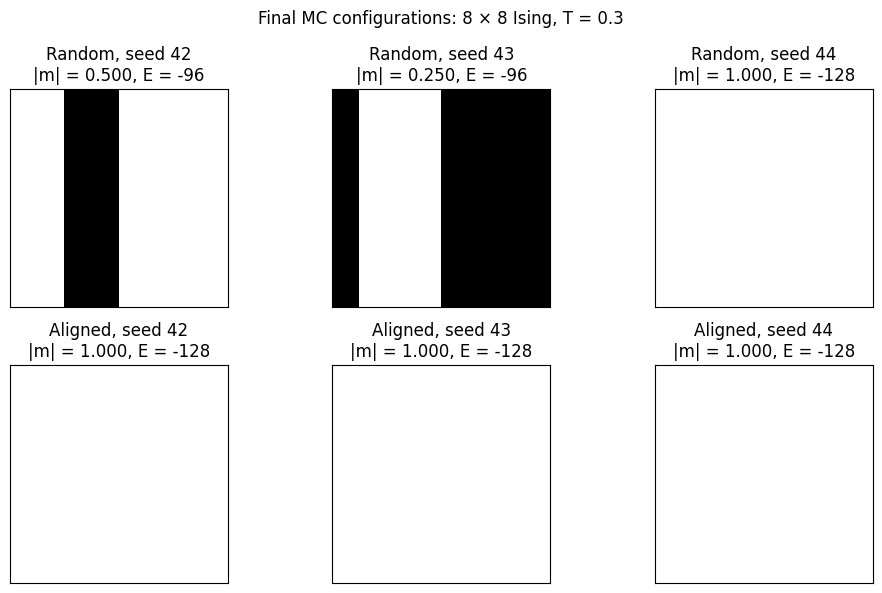

Results saved to: c:\Users\user\Documents\GitHub\thermomaps-ising\runs\ising_meeting_rerun_20261031_203228_269237\ising_low_temperature


In [11]:
if RUN_LOW_T_STUDY:
    # Fixed diagnostic settings
    L = 8
    temperature = 0.3
    warmup = 1000
    measurement_steps = 5000
    mc_seeds = (42, 43, 44)
    initializations = ("random", "aligned")

    output_dir = EXPERIMENT_ROOT / "ising_low_temperature"
    output_dir.mkdir(parents=True, exist_ok=True)

    low_t_results = []
    low_t_traces = {}
    low_t_final_states = {}




    for initialization in initializations:
        for seed in mc_seeds:
            random.seed(seed)
            np.random.seed(seed)

            simulation = IsingModel(
                sampler=SingleSpinFlipSampler,
                size=L,
                warmup=0,
                temp=temperature,
                Jx=1.0,
                Jy=1.0,
            )

            # Replace the initial state before any MC updates.
            if initialization == "aligned":
                simulation.lattice[:] = 1

            initial_state = simulation.lattice.copy()
            total_steps = warmup + measurement_steps
            trace = np.empty((total_steps + 1, 2))
            trace[0] = measure_lattice(simulation.lattice)

            print(
                f"Running: initial={initialization}, seed={seed}...",
                flush=True,
            )

            # Use the original sampler, recording the warm-up as well.
            for step in range(1, total_steps + 1):
                simulation.lattice = simulation.update()
                trace[step] = measure_lattice(simulation.lattice)

            measured = trace[warmup + 1:]
            final_state = simulation.lattice.copy()

            row = {
                "initialization": initialization,
                "seed": seed,
                "temperature": temperature,
                "size": L,
                "warmup": warmup,
                "measurement_steps": measurement_steps,
                "mean_abs_m": float(measured[:, 0].mean()),
                "mean_E": float(measured[:, 1].mean()),
                "final_abs_m": float(trace[-1, 0]),
                "final_E": float(trace[-1, 1]),
            }
            low_t_results.append(row)
            low_t_traces[(initialization, seed)] = trace
            low_t_final_states[(initialization, seed)] = final_state

            np.savez_compressed(
                output_dir / f"{initialization}_seed_{seed}.npz",
                initial_state=initial_state,
                final_state=final_state,
                abs_m=trace[:, 0],
                energy=trace[:, 1],
                settings_json=np.asarray(json.dumps(row)),
            )

            print(
                f"  Mean |m| = {row['mean_abs_m']:.4f}, "
                f"mean E = {row['mean_E']:.3f}",
                flush=True,
            )

    (output_dir / "summary.json").write_text(
        json.dumps(low_t_results, indent=2),
        encoding="utf-8",
    )

    # Show final configurations without selecting favorable examples.
    fig, axes = plt.subplots(2, 3, figsize=(10, 6))

    for i, initialization in enumerate(initializations):
        for j, seed in enumerate(mc_seeds):
            state = low_t_final_states[(initialization, seed)]
            abs_m, energy = measure_lattice(state)

            axes[i, j].imshow(
                state, cmap="gray", vmin=-1, vmax=1,
                interpolation="nearest",
            )
            axes[i, j].set_title(
                f"{initialization.capitalize()}, seed {seed}\n"
                f"|m| = {abs_m:.3f}, E = {energy:.0f}"
            )
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])

    fig.suptitle("Final MC configurations: 8 × 8 Ising, T = 0.3")
    fig.tight_layout()
    fig.savefig(output_dir / "final_configurations.png", dpi=180)
    plt.show()

    print("Results saved to:", output_dir)


### A10. Original-MC time traces


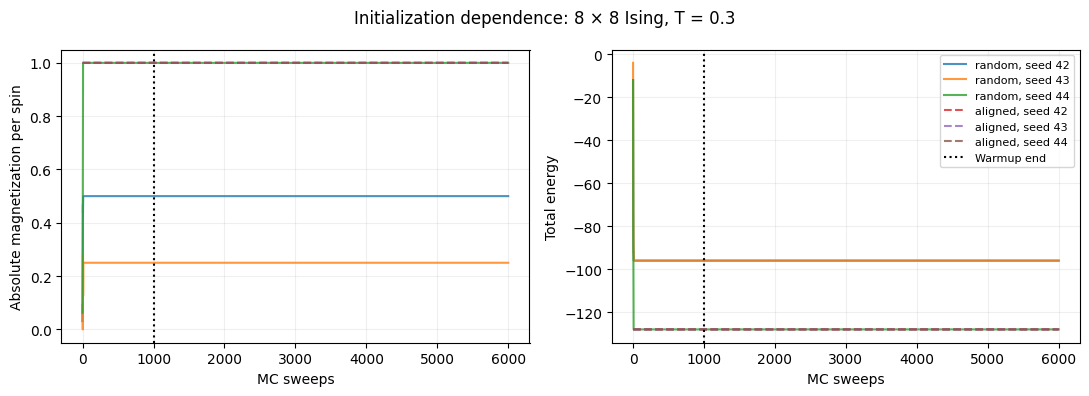

In [12]:
if RUN_LOW_T_STUDY:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    for initialization in initializations:
        for seed in mc_seeds:
            trace = low_t_traces[(initialization, seed)]
            sweeps = np.arange(len(trace))
            label = f"{initialization}, seed {seed}"
            style = "-" if initialization == "random" else "--"

            axes[0].plot(
                sweeps, trace[:, 0], style, label=label, alpha=0.8
            )
            axes[1].plot(
                sweeps, trace[:, 1], style, label=label, alpha=0.8
            )

    for ax in axes:
        ax.axvline(warmup, color="black", linestyle=":", label="Warmup end")
        ax.set_xlabel("MC sweeps")
        ax.grid(alpha=0.2)

    axes[0].set_ylabel("Absolute magnetization per spin")
    axes[1].set_ylabel("Total energy")
    axes[1].legend(fontsize=8)

    fig.suptitle("Initialization dependence: 8 × 8 Ising, T = 0.3")
    fig.tight_layout()
    fig.savefig(output_dir / "low_temperature_traces.png", dpi=180)
    plt.show()


### A11. Same stripe at two temperatures


Running T=0.3, seed=42...
  First ground-state visit: not observed; final |m|=0.500, E=-96
Running T=0.3, seed=43...
  First ground-state visit: not observed; final |m|=0.250, E=-96
Running T=0.3, seed=44...
  First ground-state visit: not observed; final |m|=0.500, E=-96
Running T=1.0, seed=42...
  First ground-state visit: 7; final |m|=1.000, E=-128
Running T=1.0, seed=43...
  First ground-state visit: 10; final |m|=1.000, E=-128
Running T=1.0, seed=44...
  First ground-state visit: 9; final |m|=1.000, E=-128


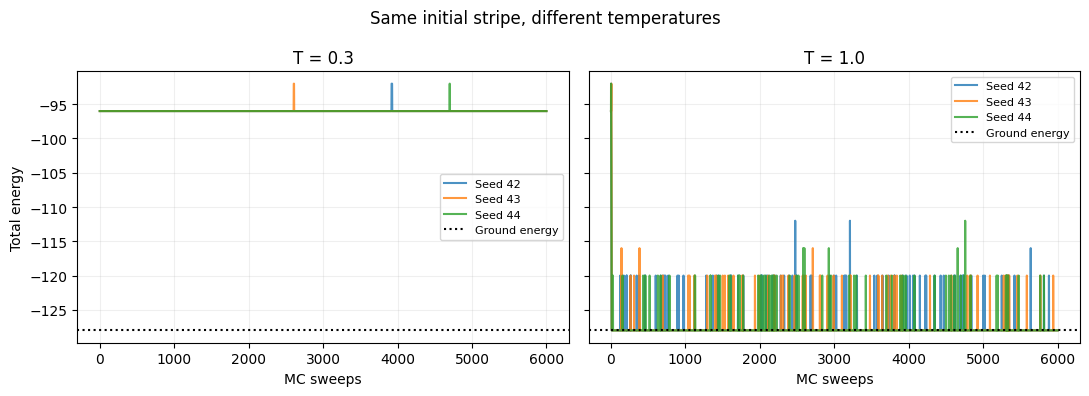

Results saved to: c:\Users\user\Documents\GitHub\thermomaps-ising\runs\ising_meeting_rerun_20261031_203228_269237\ising_low_temperature\stripe_temperature_test_20261031_211828_486098


In [13]:
if RUN_LOW_T_STUDY:
    # Reuse exactly the same stripe configuration for every run.
    stripe = low_t_final_states[("random", 42)].copy()
    L = stripe.shape[0]
    assert stripe.shape == (8, 8)
    assert measure_lattice(stripe) == (0.5, -96.0)

    temperatures = (0.3, 1.0)
    seeds = (42, 43, 44)
    steps = 6000
    ground_energy = -2 * L * L

    run_stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    save_dir = (
        EXPERIMENT_ROOT / "ising_low_temperature"
        / f"stripe_temperature_test_{run_stamp}"
    )
    save_dir.mkdir(parents=True, exist_ok=False)

    results = []
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

    for ax, temperature in zip(axes, temperatures):
        for seed in seeds:
            simulation = IsingModel(
                sampler=SingleSpinFlipSampler,
                size=L,
                warmup=0,
                temp=temperature,
                Jx=1.0,
                Jy=1.0,
            )
            simulation.lattice[:] = stripe

            # Reset randomness after construction and initialization.
            random.seed(seed)
            np.random.seed(seed)

            trace = np.empty((steps + 1, 2))
            trace[0] = measure_lattice(simulation.lattice)

            print(f"Running T={temperature}, seed={seed}...", flush=True)

            for step in range(1, steps + 1):
                simulation.lattice = simulation.update()
                trace[step] = measure_lattice(simulation.lattice)

            # First observed ground-state visit, measured at sweep boundaries.
            hits = np.flatnonzero(trace[:, 1] == ground_energy)
            first_hit = int(hits[0]) if len(hits) else None

            row = {
                "temperature": temperature,
                "seed": seed,
                "size": L,
                "sweeps": steps,
                "first_ground_state_sweep": first_hit,
                "final_abs_m": float(trace[-1, 0]),
                "final_E": float(trace[-1, 1]),
            }
            results.append(row)

            np.savez_compressed(
                save_dir / f"T_{temperature}_seed_{seed}.npz",
                initial_state=stripe,
                final_state=simulation.lattice.copy(),
                abs_m=trace[:, 0],
                energy=trace[:, 1],
                settings_json=np.asarray(json.dumps(row)),
            )

            hit_text = str(first_hit) if first_hit is not None else "not observed"
            print(
                f"  First ground-state visit: {hit_text}; "
                f"final |m|={trace[-1, 0]:.3f}, E={trace[-1, 1]:.0f}",
                flush=True,
            )

            ax.plot(trace[:, 1], label=f"Seed {seed}", alpha=0.8)

        ax.axhline(
            ground_energy, color="black", linestyle=":", label="Ground energy"
        )
        ax.set_title(f"T = {temperature}")
        ax.set_xlabel("MC sweeps")
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)

    axes[0].set_ylabel("Total energy")
    fig.suptitle("Same initial stripe, different temperatures")
    fig.tight_layout()
    fig.savefig(save_dir / "temperature_comparison.png", dpi=180)
    plt.show()

    (save_dir / "summary.json").write_text(
        json.dumps(results, indent=2), encoding="utf-8"
    )
    print("Results saved to:", save_dir)


### A12. Added Wolff implementation and basic checks


In [14]:
if RUN_LOW_T_STUDY:
    def _flip_cluster(spins, p_add, rng):
        """Grow and flip one cluster with periodic boundaries, in place."""
        rows, cols = spins.shape
        x = int(rng.integers(rows))
        y = int(rng.integers(cols))
        original_spin = spins[x, y]

        visited = np.zeros(spins.shape, dtype=bool)
        visited[x, y] = True
        stack = [(x, y)]
        cluster = [(x, y)]

        while stack:
            x, y = stack.pop()
            neighbors = (
                ((x + 1) % rows, y),
                ((x - 1) % rows, y),
                (x, (y + 1) % cols),
                (x, (y - 1) % cols),
            )

            for nx, ny in neighbors:
                if visited[nx, ny]:
                    continue
                if spins[nx, ny] != original_spin:
                    continue
                if rng.random() < p_add:
                    visited[nx, ny] = True
                    stack.append((nx, ny))
                    cluster.append((nx, ny))

        for x, y in cluster:
            spins[x, y] *= -1

        return len(cluster)


    def wolff_step(spins, temperature, rng, J=1.0):
        """One Wolff cluster update for the zero-field ferromagnetic Ising model."""
        if temperature <= 0 or J <= 0:
            raise ValueError("Temperature and J must be positive.")
        if spins.ndim != 2 or min(spins.shape) < 3:
            raise ValueError("Use a 2D lattice with both dimensions >= 3.")
        if not np.isin(spins, (-1, 1)).all():
            raise ValueError("Spins must be -1 or +1.")

        p_add = -np.expm1(-2.0 * J / temperature)
        return _flip_cluster(spins, p_add, rng)


    # Deterministic test helper: start at (0, 0) and accept every positive p.
    class TestRNG:
        def integers(self, high):
            return 0

        def random(self):
            return 0.0


    # Test 1: p_add = 0 must flip exactly one spin.
    state = np.ones((4, 4), dtype=np.int8)
    assert _flip_cluster(state, 0.0, TestRNG()) == 1
    assert np.count_nonzero(state == -1) == 1

    # Test 2: four corners connect through BOTH periodic boundaries.
    state = -np.ones((4, 4), dtype=np.int8)
    state[0, 0] = state[0, -1] = state[-1, 0] = state[-1, -1] = 1
    assert _flip_cluster(state, 1.0, TestRNG()) == 4
    assert np.all(state == -1)

    # Test 3: identical initial states and seeds reproduce the same updates.
    a = np.random.default_rng(100).choice([-1, 1], size=(8, 8))
    b = a.copy()
    rng_a = np.random.default_rng(42)
    rng_b = np.random.default_rng(42)

    for _ in range(20):
        size_a = wolff_step(a, 2.5, rng_a)
        size_b = wolff_step(b, 2.5, rng_b)
        assert size_a == size_b
        assert np.array_equal(a, b)

    print("Single-spin limit: PASS")
    print("Periodic boundary connections: PASS")
    print("Seed reproducibility: PASS")
    print("Next: validate sampling against exact 3 x 3 enumeration.")


Single-spin limit: PASS
Periodic boundary connections: PASS
Seed reproducibility: PASS
Next: validate sampling against exact 3 x 3 enumeration.


### A13. Exact 3 × 3 enumeration validation


In [15]:
if RUN_LOW_T_STUDY:
    # Enumerate every configuration of the 3 x 3 periodic Ising model.
    check_L = 3
    n_spins = check_L**2
    state_ids = np.arange(2**n_spins, dtype=np.int64)
    bits = (state_ids[:, None] >> np.arange(n_spins)) & 1
    all_states = (2 * bits - 1).reshape(-1, check_L, check_L)

    # Compute exact energies independently using an explicit bond list.
    bonds = []
    for x in range(check_L):
        for y in range(check_L):
            bonds.append(((x, y), ((x + 1) % check_L, y)))
            bonds.append(((x, y), (x, (y + 1) % check_L)))

    exact_energies = np.zeros(len(all_states), dtype=float)
    for (x, y), (nx, ny) in bonds:
        exact_energies -= all_states[:, x, y] * all_states[:, nx, ny]

    exact_abs_m = np.abs(all_states.mean(axis=(1, 2)))

    # Verify the measurement function against the explicit bond calculation.
    measured_energies = np.array([
        measure_lattice(state)[1] for state in all_states
    ])
    assert np.array_equal(measured_energies, exact_energies)
    assert exact_energies.min() == -18
    assert np.count_nonzero(exact_energies == -18) == 2

    check_temperatures = (2.5, 4.0)
    check_seeds = (42, 43, 44)
    burn_in = 1000
    n_samples = 20000
    block_size = 200

    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    check_dir = (
        EXPERIMENT_ROOT / "ising_low_temperature"
        / f"wolff_exact_check_{stamp}"
    )
    check_dir.mkdir(parents=True, exist_ok=False)
    validation_results = []

    for temperature in check_temperatures:
        # Shift energies for numerically stable Boltzmann weights.
        weights = np.exp(
            -(exact_energies - exact_energies.min()) / temperature
        )
        probabilities = weights / weights.sum()

        target_m = float(probabilities @ exact_abs_m)
        target_E = float(probabilities @ exact_energies)

        print(f"\nT = {temperature}")
        print(f"Exact: |m| = {target_m:.6f}, E = {target_E:.6f}")

        for seed in check_seeds:
            rng = np.random.default_rng(seed)
            state = rng.choice([-1, 1], size=(check_L, check_L))

            for _ in range(burn_in):
                wolff_step(state, temperature, rng)

            observations = np.empty((n_samples, 2))
            for i in range(n_samples):
                wolff_step(state, temperature, rng)
                observations[i] = measure_lattice(state)

            # Estimate uncertainty from blocks, not individual correlated frames.
            block_means = observations.reshape(-1, block_size, 2).mean(axis=1)
            means = observations.mean(axis=0)
            sem = block_means.std(axis=0, ddof=1) / np.sqrt(len(block_means))

            row = {
                "temperature": temperature,
                "seed": seed,
                "size": check_L,
                "burn_in_cluster_updates": burn_in,
                "samples": n_samples,
                "block_size": block_size,
                "exact_abs_m": target_m,
                "exact_E": target_E,
                "mean_abs_m": float(means[0]),
                "mean_E": float(means[1]),
                "block_sem_abs_m": float(sem[0]),
                "block_sem_E": float(sem[1]),
            }
            validation_results.append(row)

            np.savez_compressed(
                check_dir / f"T_{temperature}_seed_{seed}.npz",
                observations=observations,
                block_means=block_means,
                settings_json=np.asarray(json.dumps(row)),
            )

            print(
                f"Seed {seed}: "
                f"|m| = {means[0]:.6f} +/- {sem[0]:.6f}; "
                f"E = {means[1]:.6f} +/- {sem[1]:.6f}"
            )

    (check_dir / "summary.json").write_text(
        json.dumps(validation_results, indent=2),
        encoding="utf-8",
    )

    print("\nUncertainties are approximate block-based standard errors.")
    print("Results saved to:", check_dir)



T = 2.5
Exact: |m| = 0.816861, E = -13.159102
Seed 42: |m| = 0.814500 +/- 0.002296; E = -13.114800 +/- 0.057323
Seed 43: |m| = 0.816322 +/- 0.002328; E = -13.135200 +/- 0.056810
Seed 44: |m| = 0.814867 +/- 0.002173; E = -13.108600 +/- 0.051284

T = 4.0
Exact: |m| = 0.542075, E = -6.723062
Seed 42: |m| = 0.540656 +/- 0.002577; E = -6.650000 +/- 0.059635
Seed 43: |m| = 0.542433 +/- 0.002583; E = -6.738400 +/- 0.058406
Seed 44: |m| = 0.541322 +/- 0.002453; E = -6.722800 +/- 0.056785

Uncertainties are approximate block-based standard errors.
Results saved to: c:\Users\user\Documents\GitHub\thermomaps-ising\runs\ising_meeting_rerun_20261031_203228_269237\ising_low_temperature\wolff_exact_check_20261031_211843_230085


### A14. Wolff at T = 0.3 from three initial states


random , seed 42: first ground visit=2, <|m|>=1.0000, <E>=-128.000, ground fraction=1.0000
random , seed 43: first ground visit=2, <|m|>=1.0000, <E>=-128.000, ground fraction=1.0000
random , seed 44: first ground visit=3, <|m|>=1.0000, <E>=-128.000, ground fraction=1.0000
aligned, seed 42: first ground visit=0, <|m|>=1.0000, <E>=-128.000, ground fraction=1.0000
aligned, seed 43: first ground visit=0, <|m|>=1.0000, <E>=-128.000, ground fraction=1.0000
aligned, seed 44: first ground visit=0, <|m|>=1.0000, <E>=-128.000, ground fraction=1.0000
stripe , seed 42: first ground visit=1, <|m|>=1.0000, <E>=-128.000, ground fraction=1.0000
stripe , seed 43: first ground visit=1, <|m|>=1.0000, <E>=-128.000, ground fraction=1.0000
stripe , seed 44: first ground visit=1, <|m|>=1.0000, <E>=-128.000, ground fraction=1.0000


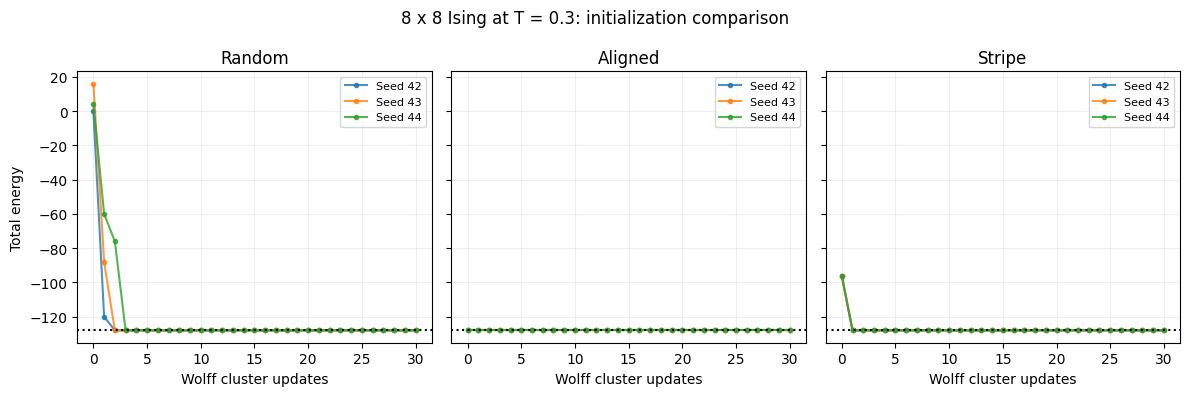

Results saved to: c:\Users\user\Documents\GitHub\thermomaps-ising\runs\ising_meeting_rerun_20261031_203228_269237\ising_low_temperature\wolff_T03_20261031_211848_105978


In [16]:
if RUN_LOW_T_STUDY:
    test_T = 0.3
    test_L = 8
    warmup_updates = 100
    measurement_updates = 1000
    total_updates = warmup_updates + measurement_updates
    test_seeds = (42, 43, 44)
    initial_types = ("random", "aligned", "stripe")

    # Preserve the previously observed trapped stripe.
    fixed_stripe = low_t_final_states[("random", 42)].copy()
    assert fixed_stripe.shape == (test_L, test_L)

    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    wolff_dir = (
        EXPERIMENT_ROOT / "ising_low_temperature"
        / f"wolff_T03_{stamp}"
    )
    wolff_dir.mkdir(parents=True, exist_ok=False)

    wolff_results = []
    fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)

    for ax, initial_type in zip(axes, initial_types):
        for seed in test_seeds:
            if initial_type == "random":
                initial_rng = np.random.default_rng(seed + 10000)
                state = initial_rng.choice([-1, 1], size=(test_L, test_L))
            elif initial_type == "aligned":
                state = np.ones((test_L, test_L), dtype=int)
            else:
                state = fixed_stripe.copy()

            initial_state = state.copy()
            rng = np.random.default_rng(seed)

            # Columns: absolute magnetization, total energy, signed magnetization.
            trace = np.empty((total_updates + 1, 3))
            trace[0, :2] = measure_lattice(state)
            trace[0, 2] = state.mean()
            cluster_sizes = np.empty(total_updates, dtype=int)

            for step in range(1, total_updates + 1):
                cluster_sizes[step - 1] = wolff_step(state, test_T, rng)
                trace[step, :2] = measure_lattice(state)
                trace[step, 2] = state.mean()

            measured = trace[warmup_updates + 1:]
            hits = np.flatnonzero(trace[:, 1] == -128)
            first_hit = int(hits[0]) if len(hits) else None

            row = {
                "initialization": initial_type,
                "seed": seed,
                "temperature": test_T,
                "size": test_L,
                "warmup_cluster_updates": warmup_updates,
                "measurement_cluster_updates": measurement_updates,
                "first_ground_state_update": first_hit,
                "mean_abs_m": float(measured[:, 0].mean()),
                "mean_E": float(measured[:, 1].mean()),
                "mean_signed_m": float(measured[:, 2].mean()),
                "ground_state_fraction": float(
                    np.mean(measured[:, 1] == -128)
                ),
            }
            wolff_results.append(row)

            np.savez_compressed(
                wolff_dir / f"{initial_type}_seed_{seed}.npz",
                initial_state=initial_state,
                final_state=state.copy(),
                trace=trace,
                cluster_sizes=cluster_sizes,
                settings_json=np.asarray(json.dumps(row)),
            )

            print(
                f"{initial_type:7s}, seed {seed}: "
                f"first ground visit={first_hit}, "
                f"<|m|>={row['mean_abs_m']:.4f}, "
                f"<E>={row['mean_E']:.3f}, "
                f"ground fraction={row['ground_state_fraction']:.4f}",
                flush=True,
            )

            # Show the early relaxation without compressing it into a long trace.
            ax.plot(
                np.arange(31), trace[:31, 1],
                marker=".", label=f"Seed {seed}", alpha=0.8,
            )

        ax.axhline(-128, color="black", linestyle=":")
        ax.set_title(initial_type.capitalize())
        ax.set_xlabel("Wolff cluster updates")
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)

    axes[0].set_ylabel("Total energy")
    fig.suptitle("8 x 8 Ising at T = 0.3: initialization comparison")
    fig.tight_layout()
    fig.savefig(wolff_dir / "early_relaxation.png", dpi=180)
    plt.show()

    (wolff_dir / "summary.json").write_text(
        json.dumps(wolff_results, indent=2), encoding="utf-8"
    )
    print("Results saved to:", wolff_dir)


### A15. Full Wolff reference over the original temperature grid


T=0.3 | <|m|>=1.0000, <E>=-128.000 | random - aligned: dM=+0.0000, dE=+0.000
T=0.5 | <|m|>=1.0000, <E>=-128.000 | random - aligned: dM=+0.0000, dE=+0.000
T=0.7 | <|m|>=1.0000, <E>=-127.995 | random - aligned: dM=-0.0000, dE=+0.000
T=0.9 | <|m|>=0.9997, <E>=-127.929 | random - aligned: dM=+0.0000, dE=+0.000
T=1.1 | <|m|>=0.9985, <E>=-127.624 | random - aligned: dM=-0.0000, dE=+0.006
T=1.3 | <|m|>=0.9948, <E>=-126.731 | random - aligned: dM=+0.0000, dE=+0.000
T=1.5 | <|m|>=0.9865, <E>=-124.870 | random - aligned: dM=+0.0000, dE=-0.001
T=1.7 | <|m|>=0.9696, <E>=-121.378 | random - aligned: dM=-0.0000, dE=+0.001
T=1.9 | <|m|>=0.9374, <E>=-115.705 | random - aligned: dM=-0.0000, dE=+0.005
T=2.1 | <|m|>=0.8730, <E>=-106.595 | random - aligned: dM=-0.0000, dE=+0.002
T=2.3 | <|m|>=0.7570, <E>=-93.339 | random - aligned: dM=+0.0014, dE=-0.211
T=2.5 | <|m|>=0.6043, <E>=-78.394 | random - aligned: dM=-0.0014, dE=-0.073
T=2.7 | <|m|>=0.4684, <E>=-65.875 | random - aligned: dM=-0.0011, dE=+0.080
T=

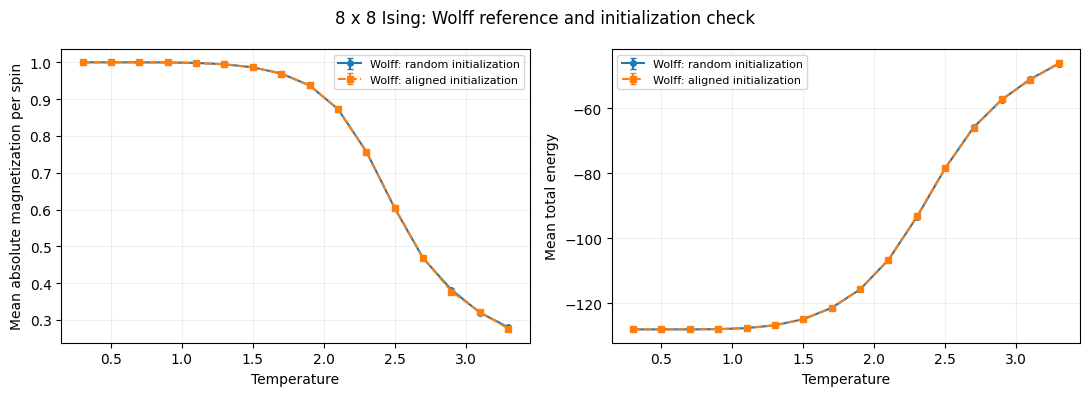


Elapsed time: 87.9 seconds
Results saved to: c:\Users\user\Documents\GitHub\thermomaps-ising\runs\ising_meeting_rerun_20261031_203228_269237\ising_low_temperature\wolff_reference_20261031_211849_452411
Error bars: approximate block-based standard errors.
Zero observed variation does not prove zero uncertainty or complete equilibrium sampling.


In [17]:
if RUN_LOW_T_STUDY:
    assert callable(globals().get("wolff_step")), (
        "Run the validated wolff_step definition first."
    )

    # Match the temperature grid in the original notebook.
    reference_config = {
        "L": 8,
        "J": 1.0,
        "temperatures": np.round(np.arange(0.3, 3.5, 0.2), 1).tolist(),
        "seeds": [42, 43, 44],
        "initializations": ["random", "aligned"],
        "warmup_updates": 1000,
        "measurement_updates": 10000,
        "block_sizes": [100, 500],
    }

    reference_dir = (
        EXPERIMENT_ROOT
        / "ising_low_temperature"
        / f"wolff_reference_{datetime.now():%Y%m%d_%H%M%S_%f}"
    )
    reference_dir.mkdir(parents=True, exist_ok=False)

    (reference_dir / "config.json").write_text(
        json.dumps(reference_config, indent=2),
        encoding="utf-8",
    )


    def reference_observables(spins):
        """Return absolute magnetization per spin and total energy."""
        abs_m = float(abs(spins.mean()))
        energy = -float(
            np.sum(
                spins * np.roll(spins, 1, axis=0)
                + spins * np.roll(spins, 1, axis=1)
            )
        )
        return np.array([abs_m, energy])


    def reference_block_sem(observations, block_size):
        """Estimate uncertainty from consecutive block means."""
        n_blocks = len(observations) // block_size
        assert n_blocks >= 2
        blocks = observations[:n_blocks * block_size].reshape(
            n_blocks, block_size, 2
        )
        block_means = blocks.mean(axis=1)
        return block_means.std(axis=0, ddof=1) / np.sqrt(n_blocks)


    reference_runs = []
    reference_curve = []
    started = time.perf_counter()

    for temperature in reference_config["temperatures"]:
        temperature_rows = []

        for initial_type in reference_config["initializations"]:
            for seed in reference_config["seeds"]:
                L = reference_config["L"]

                # Separate initialization randomness from update randomness.
                initial_rng = np.random.default_rng(seed + 10000)
                update_rng = np.random.default_rng(seed)

                if initial_type == "random":
                    spins = initial_rng.choice(
                        [-1, 1], size=(L, L)
                    ).astype(np.int8)
                else:
                    spins = np.ones((L, L), dtype=np.int8)

                initial_state = spins.copy()

                for _ in range(reference_config["warmup_updates"]):
                    wolff_step(spins, temperature, update_rng)

                n_measurements = reference_config["measurement_updates"]
                observations = np.empty((n_measurements, 2))
                cluster_sizes = np.empty(n_measurements, dtype=np.int32)

                # Measure after every cluster update.
                for step in range(n_measurements):
                    cluster_sizes[step] = wolff_step(
                        spins, temperature, update_rng
                    )
                    observations[step] = reference_observables(spins)

                means = observations.mean(axis=0)
                sem_100 = reference_block_sem(observations, 100)
                sem_500 = reference_block_sem(observations, 500)
                half = n_measurements // 2

                row = {
                    "temperature": temperature,
                    "initialization": initial_type,
                    "seed": seed,
                    "mean_abs_m": float(means[0]),
                    "mean_E": float(means[1]),
                    "block_sem_100": sem_100.tolist(),
                    "block_sem_500": sem_500.tolist(),
                    "first_half_mean": observations[:half].mean(axis=0).tolist(),
                    "second_half_mean": observations[half:].mean(axis=0).tolist(),
                    "no_observed_variation": (
                        np.ptp(observations, axis=0) == 0
                    ).tolist(),
                }
                reference_runs.append(row)
                temperature_rows.append(row)

                np.savez_compressed(
                    reference_dir
                    / f"T_{temperature:.1f}_{initial_type}_seed_{seed}.npz",
                    initial_state=initial_state,
                    final_state=spins,
                    observations=observations,
                    cluster_sizes=cluster_sizes,
                    settings_json=np.asarray(json.dumps(row)),
                )

        # Give all six equal-length runs equal weight.
        run_means = np.array([
            [r["mean_abs_m"], r["mean_E"]] for r in temperature_rows
        ])
        run_sems = np.array([
            r["block_sem_500"] for r in temperature_rows
        ])

        pooled_mean = run_means.mean(axis=0)

        # The two initializations reuse update seeds. Bound their covariance
        # instead of treating all six runs as independent.
        pair_bounds = []
        for paired_seed in reference_config["seeds"]:
            pair = [r["block_sem_500"] for r in temperature_rows
                    if r["seed"] == paired_seed]
            pair_bounds.append(np.mean(pair, axis=0))
        pooled_sem = np.sqrt(np.sum(np.asarray(pair_bounds)**2, axis=0)) / len(pair_bounds)

        random_mean = run_means[:3].mean(axis=0)
        aligned_mean = run_means[3:].mean(axis=0)

        curve_row = {
            "temperature": temperature,
            "mean_abs_m": float(pooled_mean[0]),
            "mean_E": float(pooled_mean[1]),
            "approx_sem_abs_m": float(pooled_sem[0]),
            "approx_sem_E": float(pooled_sem[1]),
            "random_minus_aligned": (random_mean - aligned_mean).tolist(),
        }
        reference_curve.append(curve_row)

        # Save progress after every completed temperature.
        (reference_dir / "runs_summary.json").write_text(
            json.dumps(reference_runs, indent=2), encoding="utf-8"
        )
        (reference_dir / "reference_curve.json").write_text(
            json.dumps(reference_curve, indent=2), encoding="utf-8"
        )

        print(
            f"T={temperature:.1f} | "
            f"<|m|>={pooled_mean[0]:.4f}, <E>={pooled_mean[1]:.3f} | "
            f"random - aligned: "
            f"dM={random_mean[0] - aligned_mean[0]:+.4f}, "
            f"dE={random_mean[1] - aligned_mean[1]:+.3f}",
            flush=True,
        )

    # Plot each initialization separately to expose disagreement.
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    for initial_type, color in [
        ("random", "tab:blue"),
        ("aligned", "tab:orange"),
    ]:
        init_means = []
        init_sems = []

        for temperature in reference_config["temperatures"]:
            rows = [
                r for r in reference_runs
                if r["temperature"] == temperature
                and r["initialization"] == initial_type
            ]
            means = np.array([
                [r["mean_abs_m"], r["mean_E"]] for r in rows
            ])
            sems = np.array([r["block_sem_500"] for r in rows])
            init_means.append(means.mean(axis=0))
            init_sems.append(np.sqrt((sems**2).sum(axis=0)) / len(rows))

        init_means = np.array(init_means)
        init_sems = np.array(init_sems)

        for column, ax in enumerate(axes):
            ax.errorbar(
                reference_config["temperatures"],
                init_means[:, column],
                yerr=init_sems[:, column],
                marker="o" if initial_type == "random" else "s",
                linestyle="-" if initial_type == "random" else "--",
                color=color,
                markersize=4,
                capsize=2,
                label=f"Wolff: {initial_type} initialization",
            )

    axes[0].set_ylabel("Mean absolute magnetization per spin")
    axes[1].set_ylabel("Mean total energy")

    for ax in axes:
        ax.set_xlabel("Temperature")
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)

    fig.suptitle("8 x 8 Ising: Wolff reference and initialization check")
    fig.tight_layout()
    fig.savefig(reference_dir / "reference_curve.png", dpi=180)
    plt.show()

    print(f"\nElapsed time: {time.perf_counter() - started:.1f} seconds")
    print("Results saved to:", reference_dir)
    print("Error bars: approximate block-based standard errors.")
    print(
        "Zero observed variation does not prove zero uncertainty "
        "or complete equilibrium sampling."
    )


### A16. Compare the original TM checkpoint with the corrected reference


Sampling TM at T=0.3...
  <|m|>=1.0000, <E>=-128.000
Sampling TM at T=0.5...
  <|m|>=1.0000, <E>=-128.000
Sampling TM at T=0.7...
  <|m|>=0.9999, <E>=-127.984
Sampling TM at T=0.9...
  <|m|>=0.9996, <E>=-127.904
Sampling TM at T=1.1...
  <|m|>=0.9994, <E>=-127.864
Sampling TM at T=1.3...
  <|m|>=0.9988, <E>=-127.720
Sampling TM at T=1.5...
  <|m|>=0.9922, <E>=-126.432
Sampling TM at T=1.7...
  <|m|>=0.9799, <E>=-123.712
Sampling TM at T=1.9...
  <|m|>=0.9303, <E>=-115.536
Sampling TM at T=2.1...
  <|m|>=0.8625, <E>=-106.176
Sampling TM at T=2.3...
  <|m|>=0.7831, <E>=-95.808
Sampling TM at T=2.5...
  <|m|>=0.6877, <E>=-84.640
Sampling TM at T=2.7...
  <|m|>=0.5791, <E>=-73.688
Sampling TM at T=2.9...
  <|m|>=0.4914, <E>=-64.792
Sampling TM at T=3.1...
  <|m|>=0.4264, <E>=-58.592
Sampling TM at T=3.3...
  <|m|>=0.3804, <E>=-54.824


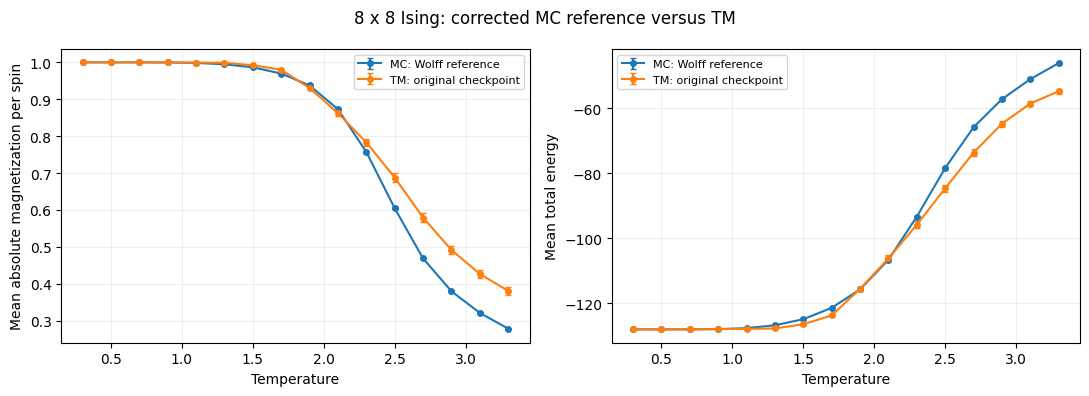


Elapsed time: 826.1 seconds
Results saved to: c:\Users\user\Documents\GitHub\thermomaps-ising\runs\ising_meeting_rerun_20261031_203228_269237\ising_low_temperature\corrected_mc_tm_20261031_212017_357580
Error bars describe sampling uncertainty, not training-seed variability.
MC errors are approximate block-based estimates.
No observed fluctuations at low T do not establish zero uncertainty.


In [18]:
if RUN_FINAL_COMPARISON:
    reference_dir = reference_dir if RUN_LOW_T_STUDY else EXISTING_REFERENCE
    assert (reference_dir / "reference_curve.json").is_file(), "Set EXISTING_REFERENCE or run the low-temperature study."

    # Load the saved MC reference.
    mc_reference_dir = Path(reference_dir)
    mc_rows = json.loads(
        (mc_reference_dir / "reference_curve.json").read_text(encoding="utf-8")
    )
    mc_runs = json.loads(
        (mc_reference_dir / "runs_summary.json").read_text(encoding="utf-8")
    )

    # Select the original checkpoint explicitly.
    tm_checkpoint_path = ORIGINAL_CHECKPOINT
    assert tm_checkpoint_path.is_file(), "Original checkpoint not found."

    tm_checkpoint_hash = hashlib.sha256(
        tm_checkpoint_path.read_bytes()
    ).hexdigest()

    expected_hash = (
        "a5f2828905a3cf100d66beee7c35ca82427"
        "a0db41121945e10461917e5c8d88e"
    )
    assert tm_checkpoint_hash == expected_hash, (
        "Checkpoint differs from the original checkpoint we checked. "
        "Stop and verify its identity."
    )

    comparison_dir = (
        EXPERIMENT_ROOT
        / "ising_low_temperature"
        / f"corrected_mc_tm_{datetime.now():%Y%m%d_%H%M%S_%f}"
    )
    comparison_dir.mkdir(parents=True, exist_ok=False)

    # Rebuild the original architecture and sampling setup.
    comparison_model = Unet2D(
        dim=16,
        dim_mults=(1, 2, 4),
        resnet_block_groups=8,
        channels=2,
    )

    saved_checkpoint = torch.load(
        tm_checkpoint_path,
        map_location="cpu",
        weights_only=True,
    )
    comparison_model.load_state_dict(saved_checkpoint["model"], strict=True)

    comparison_backbone = ConvBackbone(
        model=comparison_model,
        data_shape=8,
        target_shape=8,
        num_dims=4,
        lr=1e-3,
        eval_mode="train",
    )

    comparison_prior = GlobalEquilibriumHarmonicPrior(
        shape=(1, 2, 8, 8),
        channels_info={"coordinate": [0], "fluctuation": [1]},
    )

    comparison_sampler = SteeredDiffusionSampler(
        VPDiffusion(num_diffusion_timesteps=100),
        comparison_backbone,
        loader=None,
        prior=comparison_prior,
        pred_type="noise",
    )

    comparison_config = {
        "checkpoint": str(tm_checkpoint_path),
        "checkpoint_sha256": tm_checkpoint_hash,
        "mc_reference_directory": str(mc_reference_dir),
        "temperatures": [r["temperature"] for r in mc_rows],
        "sampling_seed": 2026,
        "num_samples_per_temperature": 500,
        "batch_size": 20,
        "gamma": 1,
        "eta": 1,
        "torch_version": str(torch.__version__),
        "device": "cpu",
    }

    (comparison_dir / "config.json").write_text(
        json.dumps(comparison_config, indent=2),
        encoding="utf-8",
    )

    tm_comparison_rows = []
    started = time.perf_counter()

    for temperature in comparison_config["temperatures"]:
        print(f"Sampling TM at T={temperature:.1f}...", flush=True)

        # Reset immediately before sampling.
        # Reusing a seed across temperatures correlates their sampling noise.
        random.seed(comparison_config["sampling_seed"])
        np.random.seed(comparison_config["sampling_seed"])
        torch.manual_seed(comparison_config["sampling_seed"])

        with torch.no_grad():
            generated = comparison_sampler.sample_loop(
                num_samples=500,
                batch_size=20,
                temperature=float(temperature),
                gamma=1,
                eta=1,
            ).detach().cpu()

        assert generated.shape == (500, 2, 8, 8)
        assert torch.isfinite(generated).all()

        spins = torch.sign(generated[:, 0]).to(torch.float64)
        assert (spins != 0).all(), "Zero coordinates need a decoding rule."

        abs_m = spins.mean(dim=(1, 2)).abs().numpy()
        energy = -(
            spins * torch.roll(spins, shifts=1, dims=1)
            + spins * torch.roll(spins, shifts=1, dims=2)
        ).sum(dim=(1, 2)).numpy()

        row = {
            "temperature": temperature,
            "mean_abs_m": float(abs_m.mean()),
            "mean_E": float(energy.mean()),
            "sem_abs_m": float(abs_m.std(ddof=1) / np.sqrt(len(abs_m))),
            "sem_E": float(energy.std(ddof=1) / np.sqrt(len(energy))),
        }
        tm_comparison_rows.append(row)

        np.savez_compressed(
            comparison_dir / f"tm_T_{temperature:.1f}.npz",
            generated=generated.numpy(),
            abs_m=abs_m,
            energy=energy,
        )
        (comparison_dir / "tm_summary.json").write_text(
            json.dumps(tm_comparison_rows, indent=2),
            encoding="utf-8",
        )

        print(
            f"  <|m|>={row['mean_abs_m']:.4f}, "
            f"<E>={row['mean_E']:.3f}",
            flush=True,
        )

    # Compute MC error estimates without treating paired initializations
    # using the same update seed as independent.
    mc_errors = []

    for temperature in comparison_config["temperatures"]:
        rows = [r for r in mc_runs if r["temperature"] == temperature]
        seeds = sorted({r["seed"] for r in rows})

        pair_sem_bounds = []
        for seed in seeds:
            paired = [r for r in rows if r["seed"] == seed]
            assert len(paired) == 2
            # Conservative covariance bound for the two initializations.
            pair_sem_bounds.append(
                np.mean([r["block_sem_500"] for r in paired], axis=0)
            )

        pair_sem_bounds = np.asarray(pair_sem_bounds)
        mc_errors.append(
            np.sqrt(np.sum(pair_sem_bounds**2, axis=0)) / len(seeds)
        )

    mc_errors = np.asarray(mc_errors)
    temperatures_plot = np.array(comparison_config["temperatures"])

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    for column, (mean_key, sem_key, ylabel) in enumerate([
        ("mean_abs_m", "sem_abs_m", "Mean absolute magnetization per spin"),
        ("mean_E", "sem_E", "Mean total energy"),
    ]):
        axes[column].errorbar(
            temperatures_plot,
            [r[mean_key] for r in mc_rows],
            yerr=mc_errors[:, column],
            color="tab:blue",
            marker="o",
            markersize=4,
            capsize=2,
            label="MC: Wolff reference",
        )
        axes[column].errorbar(
            temperatures_plot,
            [r[mean_key] for r in tm_comparison_rows],
            yerr=[r[sem_key] for r in tm_comparison_rows],
            color="tab:orange",
            marker="o",
            markersize=4,
            capsize=2,
            label="TM: original checkpoint",
        )
        axes[column].set_xlabel("Temperature")
        axes[column].set_ylabel(ylabel)
        axes[column].grid(alpha=0.2)
        axes[column].legend(fontsize=8)

    fig.suptitle("8 x 8 Ising: corrected MC reference versus TM")
    fig.tight_layout()
    fig.savefig(comparison_dir / "corrected_mc_tm.png", dpi=200)
    plt.show()

    print(f"\nElapsed time: {time.perf_counter() - started:.1f} seconds")
    print("Results saved to:", comparison_dir)
    print("Error bars describe sampling uncertainty, not training-seed variability.")
    print("MC errors are approximate block-based estimates.")
    print("No observed fluctuations at low T do not establish zero uncertainty.")


### Provenance

- Original checkpoint: `C:/content/models/model_19.pt`, saved epoch 19.
- Checkpoint SHA256: `a5f2828905a3cf100d66beee7c35ca82427a0db41121945e10461917e5c8d88e`.
- Controlled training-data SHA256: `dfa8b62457a29a01ed22d87841ea3627d2839fbf8839d3d61c4997fded0458db`.
- Recorded final reference: `runs/ising_low_temperature/wolff_reference_20261031_195629_751347`.
- Recorded final comparison: `runs/ising_low_temperature/corrected_mc_tm_20261031_200227_380071`.
- Original notebook cell indices are retained in appendix cell metadata (zero-based).

For a new run, report its own environment, hashes and outputs. Do not relabel these archived figures as results of a later rerun.
